# Prueba ANOVA de una vía
Aplicado a los salarios de docentes según su nivel de escolaridad registrado(ENOE- cs_p13_1).

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import scipy.integrate as integrate
from scipy.special import gamma as gamma
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def Fdist(f, nu1, nu2):
    return gamma((nu1 + nu2) * 0.5) * (nu1 / nu2) ** (nu1 * 0.5) / (gamma(nu1 * 0.5) * gamma(nu2 * 0.5)) * f**(nu1 * 0.5 - 1.0) / (1.0 + nu1 * f / nu2)**((nu1 + nu2) * 0.5)

In [4]:
# Cargar el dataset
df = pd.read_csv("../data/processed/docentes_enoe_sin_anomalias.csv", low_memory=False)

#Limpiar y preparar variables
df["ingocup"] = pd.to_numeric(df["ingocup"], errors="coerce")
df["cs_p13_1"] = pd.to_numeric(df["cs_p13_1"], errors="coerce")
df_clean = df.dropna(subset=["ingocup", "cs_p13_1"]).copy()
df_clean = df_clean[df_clean["ingocup"] > 0]

# Crear un diccionario para mapear los códigos de la ENOE a etiquetas legibles
mapeo_escolaridad = {
    2.0: "Primaria",
    3.0: "Secundaria",
    4.0: "Preparatoria",
    5.0: "Normal Básica",
    6.0: "Carrera Técnica",
    7.0: "Licenciatura",
    8.0: "Maestría",
    9.0: "Doctorado",
}

# Mapear los valores en una nueva columna o directamente para la gráfica
df_clean["nivel_educativo"] = df_clean["cs_p13_1"].map(mapeo_escolaridad)

In [5]:
def ejecutar_anova():
    print("=== PRUEBA ANOVA: SALARIOS POR NIVEL DE ESCOLARIDAD ===")

    # Agrupar los datos reales por nivel educativo (tratamientos)
    grupos = [group["ingocup"].values for name, group in df_clean.groupby("cs_p13_1") if len(group) > 5]
    
    if len(grupos) < 2:
        print("Error: No hay suficientes grupos de escolaridad con datos válidos.")
        return

    k = len(grupos) # Número de tratamientos (niveles de escolaridad)
    n_arr = np.asarray([len(g) for g in grupos])
    N = np.sum(n_arr) # Número total de observaciones

    todos_los_datos = np.concatenate(grupos)
    suma_total = np.sum(todos_los_datos)
    y_bar_general = suma_total / N

    # Medias de cada grupo de escolaridad
    y_bar_arr = np.asarray([np.mean(g) for g in grupos])

    # Métricas y Sumas de Cuadrados 
    SSA = np.sum(n_arr * (y_bar_arr - y_bar_general)**2) # Suma de cuadrados entre grupos 
    SST = np.sum((todos_los_datos - y_bar_general)**2)    # Suma de cuadrados total
    SSE = SST - SSA                                     # Suma de cuadrados del error

    v1 = k - 1          # Grados de libertad del factor
    v2 = N - k          # Grados de libertad del error

    S1_sq = SSA / v1    # Varianza entre tratamientos
    S_sq = SSE / v2     # Varianza del error

    f_calc = S1_sq / S_sq

   # Búsqueda del valor crítico F 
    alpha = 0.05
    f_arr = np.linspace(0.01, 10, 5000)
    f_critico = None

    for fval in f_arr:
        prob, _ = integrate.quad(lambda x: stats.f.pdf(x, v1, v2), fval, np.inf)
        if prob <= alpha:
            f_critico = fval
            break

    print(f"Número total de observaciones (N): {N}")
    print(f"Grados de libertad: v1 = {v1}, v2 = {v2}")
    print(f"SST: {SST:,.2f} | SSA: {SSA:,.2f} | SSE: {SSE:,.2f}")
    print(f"Estadístico F calculado: {f_calc:.4f}")
    print(f"Valor crítico F, alpha={alpha}): {f_critico:.4f}")

    print("\n--- Conclusión de la Prueba ANOVA ---")
    print("H0: Las medias salariales son iguales en todos los niveles de escolaridad.")
    print("H1: Al menos un nivel de escolaridad presenta una media salarial diferente.")
    
    if f_calc > f_critico:
        print(f"Como F_calc ({f_calc:.4f}) > F_critico ({f_critico:.4f}), se RECHAZA la H0.")
        print("Conclusión: Existen diferencias estadísticamente significativas en los salarios según el nivel de escolaridad.")
    else:
        print(f"Como F_calc ({f_calc:.4f}) <= F_critico ({f_critico:.4f}), NO se rechaza la H0.")
        print("Conclusión: No hay evidencia suficiente para afirmar que los salarios difieren por escolaridad.")

ejecutar_anova()

=== PRUEBA ANOVA: SALARIOS POR NIVEL DE ESCOLARIDAD ===
Número total de observaciones (N): 1142
Grados de libertad: v1 = 6, v2 = 1135
SST: 38,758,765,298.14 | SSA: 2,311,127,175.76 | SSE: 36,447,638,122.38
Estadístico F calculado: 11.9950
Valor crítico F, alpha=0.05): 2.1083

--- Conclusión de la Prueba ANOVA ---
H0: Las medias salariales son iguales en todos los niveles de escolaridad.
H1: Al menos un nivel de escolaridad presenta una media salarial diferente.
Como F_calc (11.9950) > F_critico (2.1083), se RECHAZA la H0.
Conclusión: Existen diferencias estadísticamente significativas en los salarios según el nivel de escolaridad.


C:\Users\David\AppData\Local\Temp\ipykernel_20652\1040467886.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


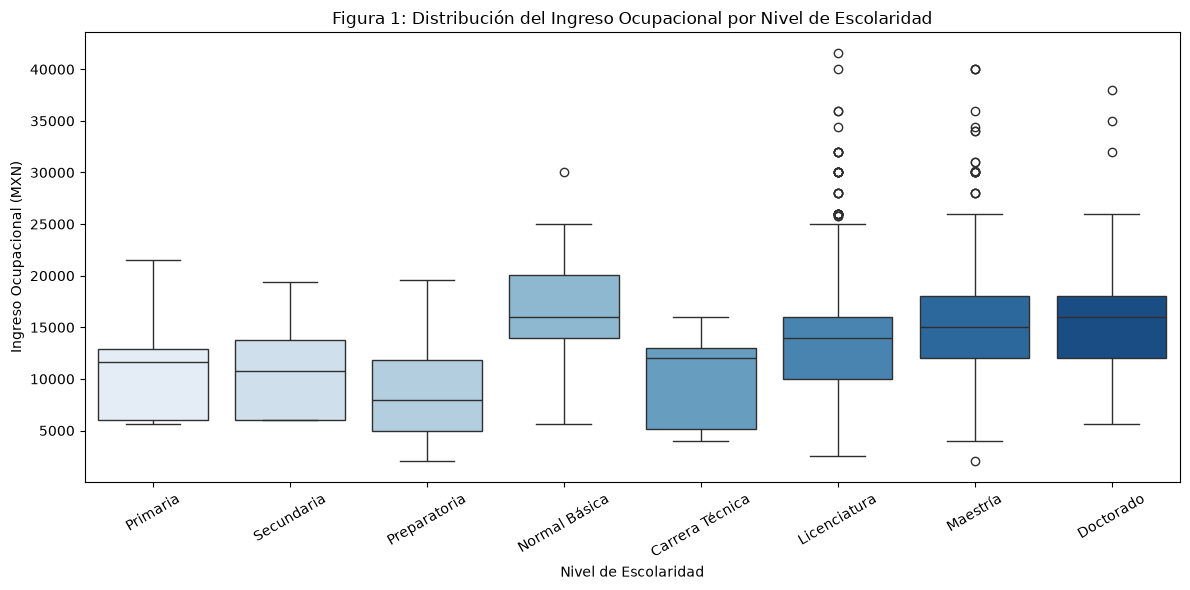

In [7]:
# Generar la gráfica usando las etiquetas de texto
plt.figure(figsize=(12, 6))
sns.boxplot(
    x="nivel_educativo",
    y="ingocup",
    data=df_clean,
    order=[
        "Primaria",
        "Secundaria",
        "Preparatoria",
        "Normal Básica",
        "Carrera Técnica",
        "Licenciatura",
        "Maestría",
        "Doctorado",
    ],
    palette="Blues",
)

plt.title(
    "Figura 1: Distribución del Ingreso Ocupacional por Nivel de Escolaridad"
)
plt.xlabel("Nivel de Escolaridad")
plt.ylabel("Ingreso Ocupacional (MXN)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("../outputs/figures/anova_escolaridad_boxplot.png", dpi=300)
plt.show()